In [6]:
import pandas as pd
import numpy as np
import os
import joblib
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


In [9]:

df = pd.read_csv('baselines_math_best_threshold_results_v2.csv')

metrics = ['accuracy', 'precision', 'recall', 'f1_score', 'auc_roc', 'log_loss']

summary = df[metrics].agg(['mean', 'std']).T
summary.columns = ['mean', 'std']
summary['report'] = summary.apply(lambda r: f"{r['mean']:.4f} ± {r['std']:.4f}", axis=1)

print(summary[['report']])

                    report
accuracy   0.8619 ± 0.0129
precision  0.8006 ± 0.0206
recall     0.9482 ± 0.0322
f1_score   0.8676 ± 0.0120
auc_roc    0.9394 ± 0.0084
log_loss   0.5267 ± 0.0307


In [10]:

df = pd.read_csv('baselines_math_default_threshold_results_v2.csv')

metrics = ['accuracy', 'precision', 'recall', 'f1_score', 'auc_roc', 'log_loss']

summary = df[metrics].agg(['mean', 'std']).T
summary.columns = ['mean', 'std']
summary['report'] = summary.apply(lambda r: f"{r['mean']:.4f} ± {r['std']:.4f}", axis=1)

print(summary[['report']])

                    report
accuracy   0.7458 ± 0.0322
precision  0.9410 ± 0.0168
recall     0.4986 ± 0.0851
f1_score   0.6477 ± 0.0688
auc_roc    0.9394 ± 0.0084
log_loss   0.5267 ± 0.0307


In [ ]:
base_path   = 'data/repetitions/'
models_path = 'models/'
features    = ['latDev', 'longDev', 'elevSat', 'loraTP', 'loraSF', 'doppler', 'alt', 'raan']

num_seeds = 10
for seed in range(num_seeds):
    print(f"\n{'='*55}")
    print(f"--- Processing Seed {seed} ---")
    
    path_train = os.path.join(base_path, f'seed_{seed}_final_train_data_transmission.csv')
    path_test = os.path.join(base_path, f'seed_{seed}_final_test_data_transmission.csv')
    path_val  = os.path.join(base_path, f'seed_{seed}_final_val_data_transmission.csv')
 
    # FIX: df_train is not used in this mathematical model — removed to avoid
    # confusion.  If it is needed in the future, add it back explicitly.
    df_train = pd.read_csv(path_train)
    df_test = pd.read_csv(path_test)
    df_val  = pd.read_csv(path_val)


    datasets = {
        "TRAIN": df_train,
        "TEST": df_test,
        "VAL": df_val
    }

    for name, df in datasets.items():
        zeros = (df['rcvOk'] == 0).sum()
        ones  = (df['rcvOk'] == 1).sum()

        total = len(df)

        pct_zeros = 100 * zeros / total
        pct_ones  = 100 * ones / total

        imbalance_ratio = max(zeros, ones) / min(zeros, ones)

        print(f"\n{name}")
        print(f"0 -> {zeros} samples ({pct_zeros:.2f}%)")
        print(f"1 -> {ones} samples ({pct_ones:.2f}%)")
        print(f"Imbalance Ratio: {imbalance_ratio:.2f}")
    
    print(df_val['rcvOk'].mean())   # tasa real de éxito
    #print(y_pred_val.mean())        # probabilidad media predicha
    #print(y_pred_val.min(), y_pred_val.max())  # rango real de predicciones


--- Procesando Seed 0 ---
GridSearch...
grid_params:  {'T_window': [1, 3, 5, 10, 20], 'k': [0.5, 1, 2, 3, 4, 5], 'alpha': [0.0001, 0.001, 0.01, 0.1, 1]}
-> Best params: {'T_window': 3, 'alpha': 0.0001, 'k': 5}
Calculating best threshold on validation set...
**************************************************
Validation set stats:
0.3307223672758921
0.1719349909637546
7.632018477897219e-25 0.9982960101140983
**************************************************
-> Best threshold in validaiton set: 0.111988
Evaluating test set with best params...


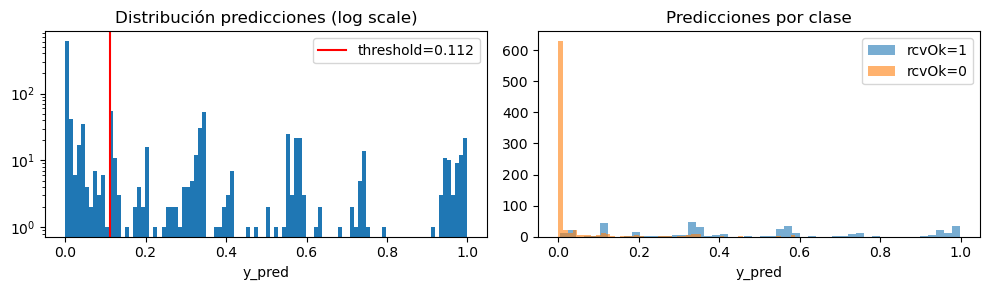

--- Procesando Seed 1 ---
GridSearch...
grid_params:  {'T_window': [1, 3, 5, 10, 20], 'k': [0.5, 1, 2, 3, 4, 5], 'alpha': [0.0001, 0.001, 0.01, 0.1, 1]}
-> Best params: {'T_window': 1, 'alpha': 0.0001, 'k': 5}
Calculating best threshold on validation set...
**************************************************
Validation set stats:
0.3741319444444444
0.26387444199525983
1.1027558888927993e-24 0.9999805153296525
**************************************************
-> Best threshold in validaiton set: 0.036007
Evaluating test set with best params...


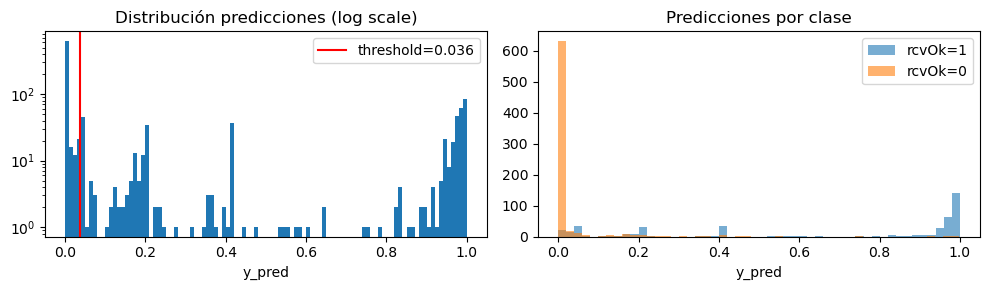

--- Procesando Seed 2 ---
GridSearch...
grid_params:  {'T_window': [1, 3, 5, 10, 20], 'k': [0.5, 1, 2, 3, 4, 5], 'alpha': [0.0001, 0.001, 0.01, 0.1, 1]}
-> Best params: {'T_window': 3, 'alpha': 0.0001, 'k': 5}
Calculating best threshold on validation set...
**************************************************
Validation set stats:
0.3949870354364736
0.20658005438353005
5.727263948653204e-24 0.9993481765976343
**************************************************
-> Best threshold in validaiton set: 0.109871
Evaluating test set with best params...


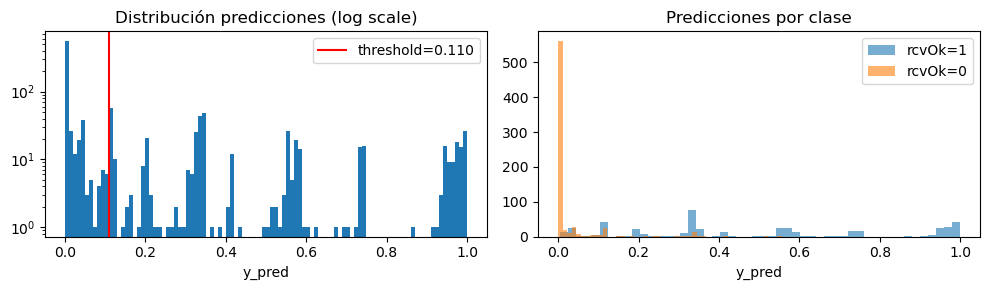

--- Procesando Seed 3 ---
GridSearch...
grid_params:  {'T_window': [1, 3, 5, 10, 20], 'k': [0.5, 1, 2, 3, 4, 5], 'alpha': [0.0001, 0.001, 0.01, 0.1, 1]}
-> Best params: {'T_window': 1, 'alpha': 0.0001, 'k': 5}
Calculating best threshold on validation set...
**************************************************
Validation set stats:
0.4086206896551724
0.29769463071683594
3.0518362053712123e-24 0.9998496982545193
**************************************************
-> Best threshold in validaiton set: 0.037946
Evaluating test set with best params...


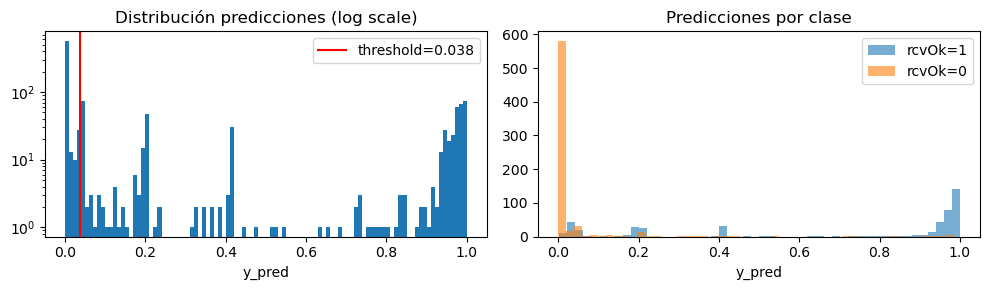

--- Procesando Seed 4 ---
GridSearch...
grid_params:  {'T_window': [1, 3, 5, 10, 20], 'k': [0.5, 1, 2, 3, 4, 5], 'alpha': [0.0001, 0.001, 0.01, 0.1, 1]}
-> Best params: {'T_window': 3, 'alpha': 0.0001, 'k': 5}
Calculating best threshold on validation set...
**************************************************
Validation set stats:
0.3975799481417459
0.20323843194419705
8.217916563315537e-25 0.9994598098272761
**************************************************
-> Best threshold in validaiton set: 0.107258
Evaluating test set with best params...


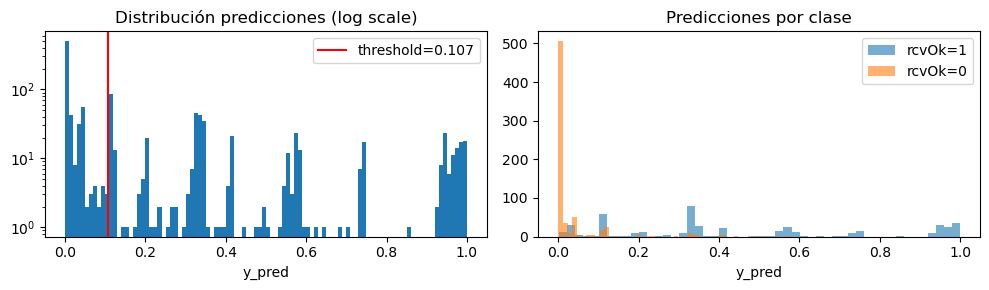

--- Procesando Seed 5 ---
GridSearch...
grid_params:  {'T_window': [1, 3, 5, 10, 20], 'k': [0.5, 1, 2, 3, 4, 5], 'alpha': [0.0001, 0.001, 0.01, 0.1, 1]}
-> Best params: {'T_window': 3, 'alpha': 0.0001, 'k': 5}
Calculating best threshold on validation set...
**************************************************
Validation set stats:
0.3944396177237185
0.21396667580213044
6.420742462702785e-25 0.9989586152434284
**************************************************
-> Best threshold in validaiton set: 0.039832
Evaluating test set with best params...


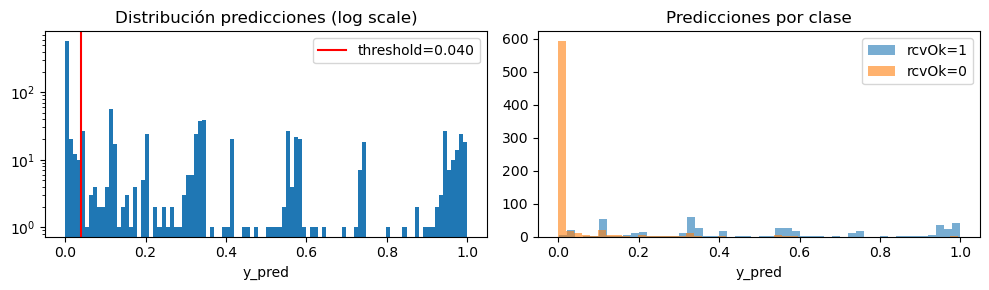

--- Procesando Seed 6 ---
GridSearch...
grid_params:  {'T_window': [1, 3, 5, 10, 20], 'k': [0.5, 1, 2, 3, 4, 5], 'alpha': [0.0001, 0.001, 0.01, 0.1, 1]}
-> Best params: {'T_window': 10, 'alpha': 0.0001, 'k': 5}
Calculating best threshold on validation set...
**************************************************
Validation set stats:
0.4574652777777778
0.20964965052007623
1.5556806071628328e-19 0.9912082598181414
**************************************************
-> Best threshold in validaiton set: 0.040510
Evaluating test set with best params...


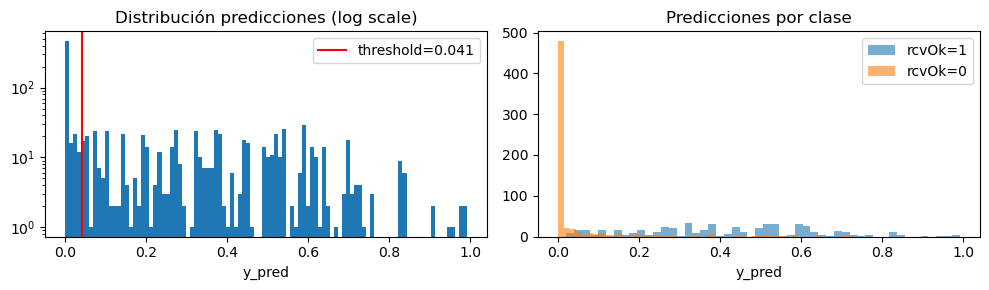

--- Procesando Seed 7 ---
GridSearch...
grid_params:  {'T_window': [1, 3, 5, 10, 20], 'k': [0.5, 1, 2, 3, 4, 5], 'alpha': [0.0001, 0.001, 0.01, 0.1, 1]}
-> Best params: {'T_window': 3, 'alpha': 0.0001, 'k': 5}
Calculating best threshold on validation set...
**************************************************
Validation set stats:
0.36724137931034484
0.21317982303167762
9.841982193825412e-27 0.9995968448344801
**************************************************
-> Best threshold in validaiton set: 0.036553
Evaluating test set with best params...


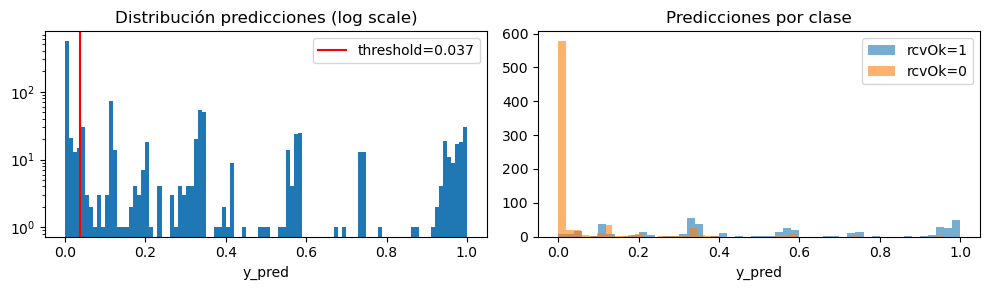

--- Procesando Seed 8 ---
GridSearch...
grid_params:  {'T_window': [1, 3, 5, 10, 20], 'k': [0.5, 1, 2, 3, 4, 5], 'alpha': [0.0001, 0.001, 0.01, 0.1, 1]}
-> Best params: {'T_window': 3, 'alpha': 0.0001, 'k': 5}
Calculating best threshold on validation set...
**************************************************
Validation set stats:
0.422680412371134
0.2273133390852651
8.39551704863862e-23 0.9991519099396927
**************************************************
-> Best threshold in validaiton set: 0.111346
Evaluating test set with best params...


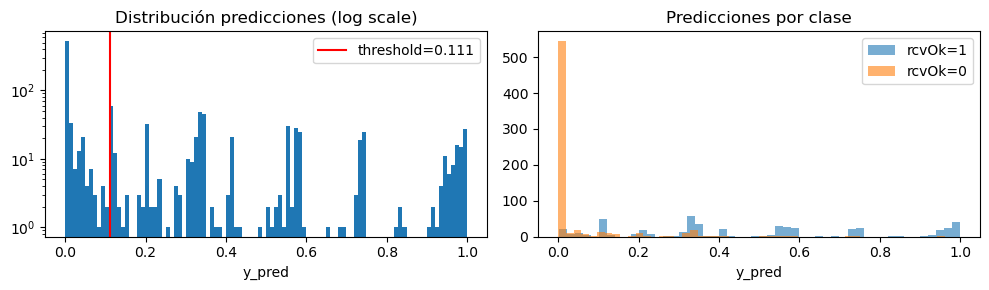

--- Procesando Seed 9 ---
GridSearch...
grid_params:  {'T_window': [1, 3, 5, 10, 20], 'k': [0.5, 1, 2, 3, 4, 5], 'alpha': [0.0001, 0.001, 0.01, 0.1, 1]}
-> Best params: {'T_window': 3, 'alpha': 0.0001, 'k': 5}
Calculating best threshold on validation set...
**************************************************
Validation set stats:
0.43583118001722654
0.22030903086690187
1.718214702231646e-22 0.9999540699301477
**************************************************
-> Best threshold in validaiton set: 0.098110
Evaluating test set with best params...


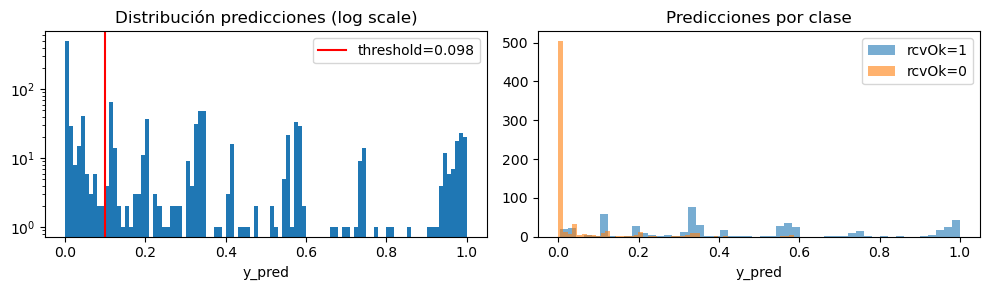

In [11]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import log_loss, roc_auc_score, f1_score
from itertools import product
import os

from sklearn.metrics import (roc_auc_score, precision_recall_curve, 
                             accuracy_score, precision_score, recall_score, f1_score)



def grid_search(df_val, grid_params):    
    print('grid_params: ', grid_params)
    #### Iterar sobre time e id_simulation
    ###df_train = df_train.sort_values('time').reset_index(drop=True)
    
    # Sort by id_simulaiton and time    
    df_val_aux = df_val.sort_values(by=['id_simulation', 'time']).reset_index(drop=True)


    BW = 125000               
    base_p_link = df_val_aux['minPowerdBm'] - df_val_aux['sensitivitydBm']
        
    BW_SF = BW / (2 ** df_val_aux['loraSF'])
    base_p_doppler = np.abs(df_val_aux['doppler']) / BW_SF
        
    ToA = df_val_aux['duration']
    y_true = df_val_aux['rcvOk'].values
    
    best_loss = float('inf')
    best_params = None

    for T_v in grid_params['T_window']:
        lambda_trx_list = []
                
        for sim_id, group in df_val_aux.groupby('id_simulation', sort=True):
            times = group['time'].values
            # Get limits (left, right) of each row accordding to the T_v/2
            lim_left = times - (T_v / 2)
            lim_right = times + (T_v / 2)

            # Get idxs of the previous calculated limits 
            idx_left = np.searchsorted(times, lim_left, side='left')
            idx_right = np.searchsorted(times, lim_right, side='right')

            # Calculate the number of trxs/registers between the idxs
            num_trx_window = np.maximum((idx_right - idx_left) - 1, 0)        
            lambda_trx = num_trx_window / T_v
            lambda_trx_list.append(lambda_trx)




        # Unimos las densidades calculadas (mantienen el mismo orden que el dataframe)
        # Concatenate traffic density , they kep the original order after the sort by id_simulation, time
        lambda_traffic = np.concatenate(lambda_trx_list)

        P_collision = np.exp(-2 * lambda_traffic * ToA)        
        #print('before second for')
        for alpha, k in product(grid_params['alpha'], grid_params['k']):            
            # Calculate p_doppler
            P_doppler = np.exp(-alpha * base_p_doppler)
            
            # Calculate p_link
            P_link = 1 / (1 + np.exp(-k * base_p_link))
            
            # Final probability
            y_pred = P_link * P_doppler * P_collision
            y_pred_clipped = np.clip(y_pred, 1e-15, 1 - 1e-15)
            
            loss = log_loss(y_true, y_pred_clipped)
            if loss < best_loss:
                best_loss = loss
                best_params = {'T_window': T_v, 'alpha': alpha, 'k': k}

    return best_params, best_loss

def evaluate_test(df_test, params):
    #### Iterar sobre time e id_simulation
    #####df_test = df_test.sort_values('time').reset_index(drop=True)
    # Sort by id_simulaiton and time    
    df_test_aux = df_test.sort_values(by=['id_simulation', 'time']).reset_index(drop=True)

    BW = 125000                           
    BW_SF = BW / (2 ** df_test_aux['loraSF'])
    
    # P_link    
    base_p_link = df_test_aux['minPowerdBm'] - df_test_aux['sensitivitydBm']
    P_link = 1 / (1 + np.exp(-params['k'] * base_p_link))
    
    # P_doppler
    base_p_doppler = np.abs(df_test_aux['doppler']) / BW_SF
    P_doppler = np.exp(-params['alpha'] * base_p_doppler)
    
    # P_collision    
    T_v = params['T_window']
    ToA = df_test_aux['duration']
    lambda_trx_list = []
    
    # Iteramos sobre cada simulación para que no haya "colisiones fantasma" entre ellas
    for sim_id, group in df_test_aux.groupby('id_simulation', sort=True):
        times = group['time'].values
        # Get limits (left, right) of each row accordding to the T_v/2
        lim_left = times - (T_v / 2)
        lim_right = times + (T_v / 2)

        # Get idxs of the previous calculated limits 
        idx_left = np.searchsorted(times, lim_left, side='left')
        idx_right = np.searchsorted(times, lim_right, side='right')

        # Calculate the number of trxs/registers between the idxs
        num_trx_window = np.maximum((idx_right - idx_left) - 1, 0)        
        lambda_trx = num_trx_window / T_v
        lambda_trx_list.append(lambda_trx)
    
    # Concatenate traffic density , they kep the original order after the sort by id_simulation, time
    lambda_traffic = np.concatenate(lambda_trx_list)
    P_collision = np.exp(-2 * lambda_traffic * ToA)    
    
    # Predicción final
    df_test_aux['P_RcvOk_Pred'] = P_link * P_doppler * P_collision
    
    y_true = df_test_aux['rcvOk'].values
    y_pred = df_test_aux['P_RcvOk_Pred'].values
    
    loss = log_loss(y_true, np.clip(y_pred, 1e-15, 1 - 1e-15))
    auc = roc_auc_score(y_true, y_pred)
    f1 = f1_score(y_true, (y_pred > 0.5).astype(int))
    
    return loss, auc, f1, y_true, y_pred

# =====================================================
# GRID SEARCH
# ======================================================
grid_params = {
    'T_window': [1, 3, 5, 10, 20],
    'k': [0.5, 1, 2, 3, 4, 5],    
    'alpha': [0.0001, 0.001, 0.01, 0.1, 1] 
}

base_path = 'data/repetitions/'
num_seeds = 10
features = ['latDev', 'longDev', 'elevSat', 'loraTP', 'loraSF', 'doppler', 'alt', 'raan']

results_list = []
metrics_history_best_threshold = []
metrics_history_default_threshold = []
for seed in range(num_seeds):
    print(f"--- Procesando Seed {seed} ---")
    
    # Construcción dinámica de nombres de archivos
    path_train = os.path.join(base_path, f'seed_{seed}_final_train_data_transmission.csv')
    path_test  = os.path.join(base_path, f'seed_{seed}_final_test_data_transmission.csv')
    path_val   = os.path.join(base_path, f'seed_{seed}_final_val_data_transmission.csv')

    # Lectura de datos
    df_train = pd.read_csv(path_train)
    df_test  = pd.read_csv(path_test)
    df_val   = pd.read_csv(path_val)

    if ' minPowerdBm' in df_train.columns:
        df_train.rename(columns={' minPowerdBm': 'minPowerdBm'}, inplace=True)
        df_test.rename(columns={' minPowerdBm': 'minPowerdBm'}, inplace=True)
        df_val.rename(columns={' minPowerdBm': 'minPowerdBm'}, inplace=True)

    print("GridSearch...")
    best_params, min_loss_train = grid_search(df_val, grid_params)
    print(f"-> Best params: {best_params}")

    print("Calculating best threshold on validation set...")
    _, _, _, y_true_val, y_pred_val = evaluate_test(df_val, best_params)
     # Find the threshold
    precisions, recalls, thresholds = precision_recall_curve(y_true_val, y_pred_val)

    print("*"*50)
    print("Validation set stats:")
    print(df_val['rcvOk'].mean())   # tasa real de éxito
    print(y_pred_val.mean())        # probabilidad media predicha
    print(y_pred_val.min(), y_pred_val.max())  # rango real de predicciones
    print("*"*50)

    # Calculate F1Score by threshold in validation set
    f1_scores_by_threshold = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-10)
    
    # Get best threshold    
    best_idx = np.argmax(f1_scores_by_threshold)
    best_threshold = thresholds[best_idx]
    print(f"-> Best threshold in validaiton set: {best_threshold:.6f}")

    print("Evaluating test set with best params...")
    loss_test, auc_test, _, y_true_test, y_pred_test = evaluate_test(df_test, best_params)
    
    # Apply best threshorld calculated in validation sset
    y_pred_test_bin = (y_pred_test > best_threshold).astype(int)

    acc_cal = accuracy_score(y_true_test, y_pred_test_bin)
    prec_cal = precision_score(y_true_test, y_pred_test_bin, zero_division=0)
    rec_cal = recall_score(y_true_test, y_pred_test_bin, zero_division=0)
    f1_cal = f1_score(y_true_test, y_pred_test_bin, zero_division=0)

    metrics_history_best_threshold.append({
        'seed': seed,
        'best_threshold': best_threshold,
        'log_loss': loss_test,
        'auc_roc': auc_test,
        'accuracy': acc_cal,
        'precision': prec_cal,
        'recall': rec_cal,
        'f1_score': f1_cal
    })
    import matplotlib.pyplot as plt

    plt.figure(figsize=(10, 3))
    plt.subplot(1, 2, 1)
    plt.hist(y_pred_val, bins=100, log=True)
    plt.axvline(best_threshold, color='red', label=f'threshold={best_threshold:.3f}')
    plt.xlabel('y_pred'); plt.title('Distribución predicciones (log scale)')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.hist(y_pred_val[y_true_val == 1], bins=50, alpha=0.6, label='rcvOk=1')
    plt.hist(y_pred_val[y_true_val == 0], bins=50, alpha=0.6, label='rcvOk=0')
    plt.xlabel('y_pred'); plt.title('Predicciones por clase')
    plt.legend()
    plt.tight_layout()
    plt.show()
    # Apply default threshorld (0.5) calculated in validation sset
    y_pred_test_bin = (y_pred_test > 0.5).astype(int)

    acc_cal = accuracy_score(y_true_test, y_pred_test_bin)
    prec_cal = precision_score(y_true_test, y_pred_test_bin, zero_division=0)
    rec_cal = recall_score(y_true_test, y_pred_test_bin, zero_division=0)
    f1_cal = f1_score(y_true_test, y_pred_test_bin, zero_division=0)

    metrics_history_default_threshold.append({
        'seed': seed,
        'default_threshold': 0.5,
        'log_loss': loss_test,
        'auc_roc': auc_test,
        'accuracy': acc_cal,
        'precision': prec_cal,
        'recall': rec_cal,
        'f1_score': f1_cal
    })
